<a href="https://colab.research.google.com/github/cauachristo-ucl/Sensorial_Map_Ucl/blob/main/Sensorial_Map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Instalando/declacarando/importando bibliotecas

In [ ]:
# 1.1 — instalar tudo e baixar o modelo
!pip install -q mediapipe gdown

!wget -q -O hand_landmarker.task \
  https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task

import os
mb = os.path.getsize("hand_landmarker.task") / 1e6
print(f"modelo: {mb:.1f} MB")
if mb < 1:
    print("!! o arquivo veio pequeno demais - rode esta celula de novo")

modelo: 7.8 MB


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("OpenCV versao:", cv2.__version__)

!pip install -q gdown
import gdown

#UPLOUD VIDEO
VIDEO = "sessao_exemplo.mp4"
FILE_ID = "1URW0Xo0zxgL1JhgeDy_Hx1aKwB_jj-e2"

if not os.path.exists(VIDEO):
    gdown.download(f"https://drive.google.com/uc?id={FILE_ID}", VIDEO, quiet=False)

print("video baixado:", os.path.getsize(VIDEO) / 1e6, "MB")

OpenCV versao: 5.0.0
video baixado: 2.503124 MB


In [ ]:
# 1.2 — imports e CHECKPOINT 0
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks.python.vision import drawing_utils as mp_draw
from mediapipe.tasks.python.vision import HandLandmarksConnections

BaseOptions        = mp.tasks.BaseOptions
HandLandmarker     = mp.tasks.vision.HandLandmarker
HandLandmarkerOpts = mp.tasks.vision.HandLandmarkerOptions
RunningMode        = mp.tasks.vision.RunningMode
CONEXOES           = list(HandLandmarksConnections.HAND_CONNECTIONS)


def mostrar(img_bgr, titulo="", tamanho=(10, 6)):
    """Mostra uma imagem BGR dentro do Colab.

    cv2.imshow() NAO funciona aqui: ele tenta abrir uma janela, e no Colab
    nao existe janela. Entao usamos o matplotlib - convertendo BGR->RGB.
    """
    plt.figure(figsize=tamanho)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(titulo, fontsize=13)
    plt.axis("off")
    plt.show()


print("mediapipe:", mp.__version__, "| opencv:", cv2.__version__)
assert os.path.exists("hand_landmarker.task"), "modelo nao encontrado - rode a celula 1.1"
print("CHECKPOINT 0 ok - ambiente pronto.")

mediapipe: 1.2.3 | opencv: 5.0.0
CHECKPOINT 0 ok - ambiente pronto.


## Definindo funções que serão usados no código

Função para identificar o ID do arquivo do Drive, através do link.

In [ ]:
# 5.1 — do link do Drive ao ID do arquivo
import re
#https://drive.google.com/file/d/1r5WSREiO7KvAUk7ZLFSICvF5TdMzgY-k/view?usp=sharing
_PADROES = [
    r"/file/d/([A-Za-z0-9_-]{10,})",    # .../file/d/ID/view
    r"[?&]id=([A-Za-z0-9_-]{10,})",     # ...open?id=ID  ou  ...uc?id=ID
    r"/d/([A-Za-z0-9_-]{10,})",         # .../d/ID/...
    r"^([A-Za-z0-9_-]{25,})$",          # o ID puro, ja copiado sozinho
]

def id_do_drive(link):
    """Extrai o ID do arquivo de um link do Google Drive.

    Aceita os varios formatos que o Drive gera. Devolve None se nao achar.
    """
    link = link.strip()
    for padrao in _PADROES:
        achou = re.search(padrao, link)
        if achou:
            return achou.group(1)
    return None

Função para 'baixar' o video do drive. **COLE O LINK DO DRIVE NO LUGAR INFORMADO**

In [ ]:
# COLE AQUI O LINK DO SEU VIDEO
LINK = "https://drive.google.com/file/d/1KEN-SDaol-V1aDtTA0mC10uOk0kqf0T1/view?usp=sharing"
import gdown

ID = id_do_drive(LINK)
if ID is None:
    raise ValueError(
        "Nao encontrei um ID neste link.\n"
        "  - e link de ARQUIVO (.../file/d/...) e nao de pasta (.../folders/...)?\n"
        "  - voce colou o link inteiro, entre aspas?")

print("ID do arquivo:", ID)

VIDEO = "sessao.mp4"
gdown.download(f"https://drive.google.com/uc?id={ID}", VIDEO, quiet=False)

if (not os.path.exists(VIDEO)) or os.path.getsize(VIDEO) < 10_000:
    raise RuntimeError(
        "O download falhou ou veio um arquivo minusculo.\n"
        "Quase sempre e PERMISSAO: volte no Drive, Compartilhar,\n"
        "e troque 'Restrito' por 'Qualquer pessoa com o link'.")

print(f"\nbaixado: {VIDEO}  ({os.path.getsize(VIDEO)/1e6:.1f} MB)")

ID do arquivo: 1KEN-SDaol-V1aDtTA0mC10uOk0kqf0T1


Downloading...
From: https://drive.google.com/uc?id=1KEN-SDaol-V1aDtTA0mC10uOk0kqf0T1
To: /content/sessao.mp4
100%|██████████| 23.8M/23.8M [00:00<00:00, 302MB/s]


baixado: sessao.mp4  (23.8 MB)


Função para normalizar a posição.

In [ ]:
def para_pixel(landmark, largura, altura):
  Xpixel = int(landmark.x * largura)
  Ypixel = int(landmark.y * altura)

  return Xpixel, Ypixel

## Inicio do código

Definir as ROIs (Por enquanto, retirado de outro código)

In [ ]:
#posição X e Y das ROIs mais sua largura (W) e altura (H)
#X =  [280, 719, 283, 726]
#Y =  [4, 4, 398, 400]
#W =  [410, 439, 415, 438]
#H =  [370, 371, 322, 320]
X =  [240, 500, 240, 520]
Y =  [4, 4, 250, 230]
W =  [240, 240, 240, 260]
H =  [220, 200, 220, 240]

Coletando algumas informações do video

In [ ]:
cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), f"o OpenCV nao conseguiu abrir {VIDEO} - grave em .mp4"

FPS      = cap.get(cv2.CAP_PROP_FPS)
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
V_LARG   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
V_ALT    = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"resolucao : {V_LARG} x {V_ALT}")
print(f"fps       : {FPS:.2f}")
print(f"quadros   : {N_FRAMES}")
print(f"duracao   : {N_FRAMES/FPS:.1f} s")
print(f"\n{FPS:.0f} quadros por segundo significa que cada quadro vale "
      f"{1000/FPS:.1f} milissegundos.")

resolucao : 848 x 478
fps       : 29.98
quadros   : 3201
duracao   : 106.8 s

30 quadros por segundo significa que cada quadro vale 33.4 milissegundos.


Aqui vamos varrer frame a frame do video pegando a posição da ponta do dedo indicador, verificar se tá dentro das Zonas e em qual zona tá .

In [ ]:
det_video = HandLandmarker.create_from_options(HandLandmarkerOpts(
    base_options=BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=RunningMode.VIDEO,
    num_hands=1,
))

#Dicionário para identificar uma zona através de um numero
Zonas = {0:"Zona1", 1:"Zona2", 2:"Zona3", 3:"Zona4"}

#vetor para guardar as zonas que o dedo indicador passou
visitas = []

falhas = 0

cap = cv2.VideoCapture(VIDEO)
trajetoria = []          # (quadro, tempo_s, x_norm, y_norm)
primeiro_frame = None
n = 0

while True:
    ok, frame = cap.read()
    if not ok:
        break                                  # o video acabou
    if primeiro_frame is None:
        primeiro_frame = frame.copy()

    #Converte o tipo de imagem de BGR para RGB
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))

    #Calcula o tempo atual do video em milissiegundos
    tempo_ms = int(1000 * n / FPS)             # tem que SEMPRE crescer

    #res armazena o resusltado da detecção. (mp_img = frame atua do video; tampo_ms = tempo atual do video)
    res = det_video.detect_for_video(mp_img, tempo_ms)

    if res.hand_landmarks:
        ponta = res.hand_landmarks[0][8]       # 8 = ponta do indicador

        trajetoria.append((n, n/FPS, ponta.x, ponta.y))

        Xpixel, Ypixel = para_pixel(ponta, V_LARG, V_ALT)

        for i in range(4):
          if X[i] < Xpixel < X[i] + W[i] and Y[i] < Ypixel < Y[i] + H[i]:
            visitas.append(Zonas[i])
          else:
            falhas =+ 1
        if falhas == 4:
          visitas.append(None)
          falhas = 0
        else:
          falhas = 0

    else:
        visitas.append(None)   # None, nunca zero
        trajetoria.append((n, n/FPS, None, None))

    n += 1
    if n % 60 == 0:
        print(f"  {n} quadros processados...")

cap.release()
print(f"\npronto: {len(visitas)} quadros")
print("quadros totais: ", n)

  60 quadros processados...
  120 quadros processados...
  180 quadros processados...
  240 quadros processados...
  300 quadros processados...
  360 quadros processados...
  420 quadros processados...
  480 quadros processados...
  540 quadros processados...
  600 quadros processados...
  660 quadros processados...
  720 quadros processados...
  780 quadros processados...
  840 quadros processados...
  900 quadros processados...
  960 quadros processados...
  1020 quadros processados...
  1080 quadros processados...
  1140 quadros processados...
  1200 quadros processados...
  1260 quadros processados...
  1320 quadros processados...
  1380 quadros processados...
  1440 quadros processados...
  1500 quadros processados...
  1560 quadros processados...
  1620 quadros processados...
  1680 quadros processados...
  1740 quadros processados...
  1800 quadros processados...
  1860 quadros processados...
  1920 quadros processados...
  1980 quadros processados...
  2040 quadros processados.

Vamos agora fazer a contagem de das Zonas visitadas e colocar em segundos

In [ ]:
#dicionário para fazer contagem
contagem = {"Zona1": 0, "Zona2": 0, "Zona3": 0, "Zona4": 0}

tempos_seg = []

tempo_fora_zona = 0

for i in range(len(visitas)):
  if visitas[i] != None:
    contagem[visitas[i]] += 1
  else:
    tempo_fora_zona += 1

print (tempo_fora_zona)
print(contagem)

tempos_seg = {name: round(valor / FPS) for name,valor in contagem.items()}
print(tempos_seg)
print(round(tempo_fora_zona/FPS))

#zona 1 = 25
#zona 2 = 15
#zona 3 = 0
#zona 4 = 37

856
{'Zona1': 648, 'Zona2': 6, 'Zona3': 414, 'Zona4': 1150}
{'Zona1': 22, 'Zona2': 0, 'Zona3': 14, 'Zona4': 38}
29


Com as informações adiquiridas anteriomente, faremos o mapa de calor

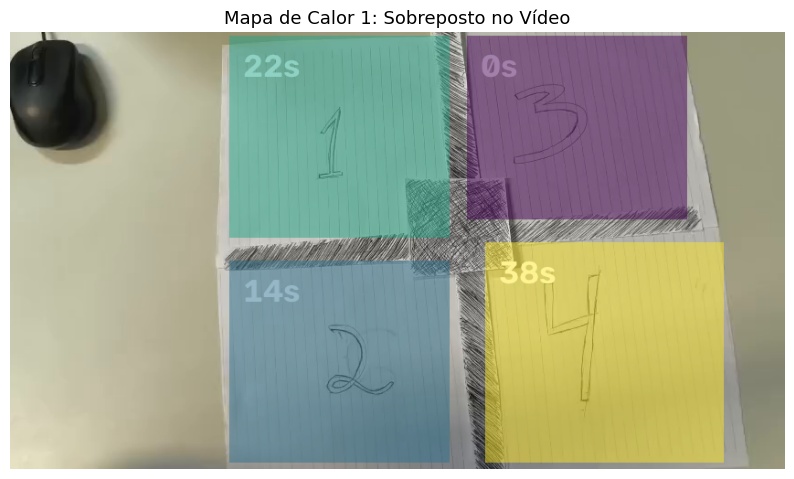

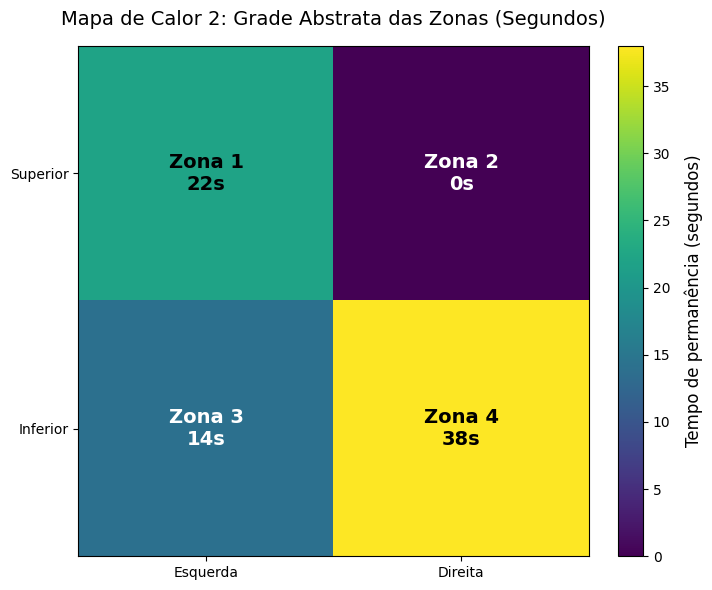

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Gerar o primeiro mapa de calor (sobreposição no frame original)
if primeiro_frame is not None and len(X) == 4:
    fundo = primeiro_frame.copy()
    overlay = fundo.copy()

    valores = list(tempos_seg.values())
    max_valor = max(valores) if max(valores) > 0 else 1
    cmap = plt.get_cmap('viridis')

    for i in range(4):
        tempo = tempos_seg.get(f"Zona{i+1}", 0)
        intensidade = tempo / max_valor
        cor_rgb = cmap(intensidade)[:3]
        cor_bgr = (int(cor_rgb[2] * 255), int(cor_rgb[1] * 255), int(cor_rgb[0] * 255))

        cv2.rectangle(
            overlay,
            (X[i], Y[i]),
            (X[i] + W[i], Y[i] + H[i]),
            cor_bgr,
            -1
        )

        cv2.putText(
            fundo,
            f"{tempo}s",
            (X[i] + 15, Y[i] + 45),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.2,
            (255, 255, 255),
            3,
            cv2.LINE_AA
        )

    alpha = 0.5
    mapa_de_calor = cv2.addWeighted(overlay, alpha, fundo, 1 - alpha, 0)
    mostrar(mapa_de_calor, 'Mapa de Calor 1: Sobreposto no Vídeo', tamanho=(10, 6))

    # 2. Gerar o segundo mapa de calor (Grade 2x2 abstrata com barra de cores/legenda)
    # Criamos uma matriz 2x2 com os valores das zonas:
    # Linha 1: Zona 1 e Zona 2 | Linha 2: Zona 3 e Zona 4
    grade_valores = np.array([
        [tempos_seg.get("Zona1", 0), tempos_seg.get("Zona2", 0)],
        [tempos_seg.get("Zona3", 0), tempos_seg.get("Zona4", 0)]
    ])

    plt.figure(figsize=(8, 6))
    # Plotar a matriz 2x2 com o mesmo colormap viridis
    im = plt.imshow(grade_valores, cmap='viridis', interpolation='nearest')

    # Configurar títulos e rótulos das células
    plt.title('Mapa de Calor 2: Grade Abstrata das Zonas (Segundos)', fontsize=14, pad=15)

    # Adicionar os valores numéricos escritos dentro de cada quadrado da grade
    for l in range(2):
        for c in range(2):
            num_zona = l * 2 + c + 1
            tempo_valor = grade_valores[l, c]
            plt.text(c, l, f"Zona {num_zona}\n{tempo_valor}s",
                     color='white' if tempo_valor < max_valor * 0.5 else 'black',
                     ha='center', va='center', fontsize=14, fontweight='bold')

    # Ajustar eixos
    plt.xticks([0, 1], ['Esquerda', 'Direita'])
    plt.yticks([0, 1], ['Superior', 'Inferior'])

    # Adicionar barra lateral de cores (Legenda do gradiente)
    cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
    cbar.set_label('Tempo de permanência (segundos)', fontsize=12, labelpad=10)

    plt.tight_layout()
    plt.show()
else:
    print("Erro: Certifique-se de que as células anteriores foram executadas com sucesso.")

Exportando as informações adiquiridas


In [ ]:
# 7.1 — juntar tudo
import json
import glob
import zipfile

# Calcular as variáveis corretas com base no que rodamos nas células anteriores
quadros_total = n
quadros_com_mao = sum(1 for v in visitas if v is not None)
taxa_deteccao = quadros_com_mao / quadros_total if quadros_total > 0 else 0

resumo = {
    "link_drive": LINK,
    "resolucao": [V_LARG, V_ALT],
    "fps": round(FPS, 2),
    "quadros_total": quadros_total,
    "quadros_com_mao": quadros_com_mao,
    "taxa_deteccao": round(taxa_deteccao, 4),
    "grade": [2, 2],  # Grade fixa de 2x2 correspondente às 4 zonas
    "tempo_por_zona_s": {
        "zona_1": float(tempos_seg.get("Zona1", 0)),
        "zona_2": float(tempos_seg.get("Zona2", 0)),
        "zona_3": float(tempos_seg.get("Zona3", 0)),
        "zona_4": float(tempos_seg.get("Zona4", 0))
    }
}

with open("resumo_desafio.json", "w") as f:
    json.dump(resumo, f, indent=2, ensure_ascii=False)
print(json.dumps(resumo, indent=2, ensure_ascii=False))

# Criar arquivo CSV simples com os tempos por zona
with open("mapa_por_zona.csv", "w") as f:
    f.write("zona,tempo_segundos\n")
    for zona, tempo in tempos_seg.items():
        f.write(f"{zona},{tempo}\n")

arquivos = ["mapa_por_zona.csv", "Dados.json"] + sorted(glob.glob("saida_*"))
with zipfile.ZipFile("Informações_do_Video.zip", "w") as z:
    for a in arquivos:
        try:
            z.write(a)
        except FileNotFoundError:
            pass

print("\nno zip:", [arq for arq in arquivos if os.path.exists(arq)])

from google.colab import files
try:
    files.download("Informações_do_Video.zip")
except Exception as e:
    print("Pronto para download (se o download automático falhar, clique na pasta lateral esquerda para baixar desafio_zona_secreta.zip).")

{
  "link_drive": "https://drive.google.com/file/d/1KEN-SDaol-V1aDtTA0mC10uOk0kqf0T1/view?usp=sharing",
  "resolucao": [
    848,
    478
  ],
  "fps": 29.98,
  "quadros_total": 3201,
  "quadros_com_mao": 2218,
  "taxa_deteccao": 0.6929,
  "grade": [
    2,
    2
  ],
  "tempo_por_zona_s": {
    "zona_1": 22.0,
    "zona_2": 0.0,
    "zona_3": 14.0,
    "zona_4": 38.0
  }
}

no zip: ['mapa_por_zona.csv', 'resumo_desafio.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>